Projeto Avaliativo — Desenvolvimento de IA para Análise Preditiva
Objetivo
DESAFIO
Atuar como Cientista de Dados para estruturar um Pipeline Preditivo completo aplicado à Indústria 4.0 para prever falhas mecânicas em equipamentos industriais.

Fase 1 — Análise Exploratória (EDA)

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('manutencao_preditiva.csv')
df.shape

print ("=== INSPECAO INICIAL DO DATASET ===")
print (f"O dataset tem {df.shape[0]} linhas e {df.shape [1]} colunas")

df.head()

print("Colunas do Dataset")
print(df.dtypes)

print(f"Total de conlunas numéricas: {df.select_dtypes(include='number').shape[1]}")
print(f"Total de colunas de texto: {df.select_dtypes(include='object').shape[1]}")

df.info()

=== INSPECAO INICIAL DO DATASET ===
O dataset tem 10000 linhas e 14 colunas
Colunas do Dataset
udi                          int64
id_produto                  object
tipo                        object
temperatura_ar_k           float64
temperatura_processo_k     float64
velocidade_rotacao_rpm     float64
torque_nm                  float64
desgaste_ferramenta_min      int64
falha_maquina                int64
falha_twf                    int64
falha_hdf                    int64
falha_pwf                    int64
falha_osf                    int64
falha_rnf                    int64
dtype: object
Total de conlunas numéricas: 12
Total de colunas de texto: 2
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   udi                      10000 non-null  int64  
 1   id_produto               10000 non-null  object 
 2   tipo       

In [47]:
df.describe()

,udi,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
count,10000.00000,9500.000000,9500.000000,9500.000000,9500.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.002158,310.000895,1539.245263,39.974168,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.001689,1.486432,180.273589,9.995453,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.100000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1504.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1613.000000,46.700000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [48]:
nulos = df.isnull().sum()
nulos_filtrados = nulos[nulos > 0]

if len(nulos_filtrados) > 0:
  print("Colunas com dados faltantes:")
  print(nulos_filtrados)

  print(f"Total de celulas vazias: {df.isnull().sum()}.")

Colunas com dados faltantes:
temperatura_ar_k          500
temperatura_processo_k    500
velocidade_rotacao_rpm    500
torque_nm                 500
dtype: int64
Total de celulas vazias: udi                          0
id_produto                   0
tipo                         0
temperatura_ar_k           500
temperatura_processo_k     500
velocidade_rotacao_rpm     500
torque_nm                  500
desgaste_ferramenta_min      0
falha_maquina                0
falha_twf                    0
falha_hdf                    0
falha_pwf                    0
falha_osf                    0
falha_rnf                    0
dtype: int64.


Fase 2 — Limpeza e Tratamento de Dados (Data Prep)

In [49]:
df['falha_maquina'].value_counts()

,count
falha_maquina,
0,9661
1,339


In [50]:
df['falha_maquina'].value_counts(normalize=True) * 100

,proportion
falha_maquina,
0,96.61
1,3.39


In [51]:
df.isnull().sum()

,0
udi,0
id_produto,0
tipo,0
temperatura_ar_k,500
temperatura_processo_k,500
velocidade_rotacao_rpm,500
torque_nm,500
desgaste_ferramenta_min,0
falha_maquina,0
falha_twf,0


In [52]:
df['temperatura_ar_k'].median()

300.1

In [53]:
df['temperatura_ar_k'] = df['temperatura_ar_k'].fillna(df['temperatura_ar_k'].median())
df['temperatura_ar_k'].isnull().sum()

np.int64(0)

In [54]:
colunas = ['temperatura_processo_k','velocidade_rotacao_rpm','torque_nm']
for coluna in colunas: df[coluna] = df[coluna].fillna(df[coluna].median())
df.isnull().sum()

,0
udi,0
id_produto,0
tipo,0
temperatura_ar_k,0
temperatura_processo_k,0
velocidade_rotacao_rpm,0
torque_nm,0
desgaste_ferramenta_min,0
falha_maquina,0
falha_twf,0


In [55]:
df.duplicated().sum()

np.int64(0)

In [56]:
df.duplicated().sum()

np.int64(0)

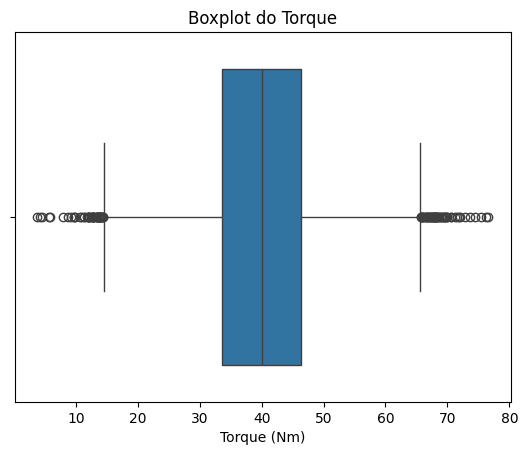

In [57]:
sns.boxplot(x=df['torque_nm'])
plt.title('Boxplot do Torque')
plt.xlabel('Torque (Nm)')
plt.show()

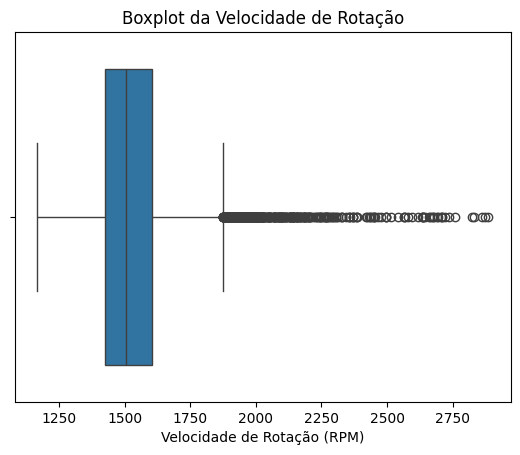

In [58]:
sns.boxplot(x=df['velocidade_rotacao_rpm'])
plt.title('Boxplot da Velocidade de Rotação')
plt.xlabel('Velocidade de Rotação (RPM)')
plt.show()

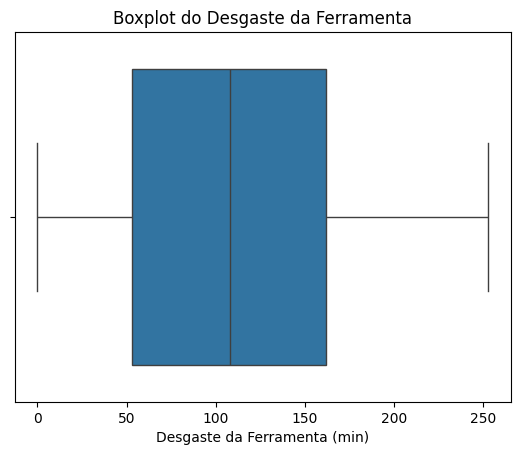

In [59]:
sns.boxplot(x=df['desgaste_ferramenta_min'])
plt.title('Boxplot do Desgaste da Ferramenta')
plt.xlabel('Desgaste da Ferramenta (min)')
plt.show()

Fase 3 — Engenharia de Atributos (Feature Engineering)

In [60]:
df['potencia'] = df['velocidade_rotacao_rpm'] * df['torque_nm']

In [61]:
df[['velocidade_rotacao_rpm', 'torque_nm', 'potencia']].head()

,velocidade_rotacao_rpm,torque_nm,potencia
0,1551.0,42.8,66382.8
1,1408.0,46.3,65190.4
2,1498.0,49.4,74001.2
3,1504.0,40.1,60310.4
4,1408.0,40.0,56320.0


In [62]:
print("Dimensões do dataset:", df.shape)
print("A coluna potencia foi criada:", 'potencia' in df.columns)

Dimensões do dataset: (10000, 15)
A coluna potencia foi criada: True


In [63]:
df.columns.tolist()

['udi',
 'id_produto',
 'tipo',
 'temperatura_ar_k',
 'temperatura_processo_k',
 'velocidade_rotacao_rpm',
 'torque_nm',
 'desgaste_ferramenta_min',
 'falha_maquina',
 'falha_twf',
 'falha_hdf',
 'falha_pwf',
 'falha_osf',
 'falha_rnf',
 'potencia']

Fase 4 — Divisão e Balanceamento dos Dados

In [64]:
y = df['falha_maquina']
X = df.drop(columns=['udi','id_produto','falha_maquina','falha_twf','falha_hdf','falha_pwf','falha_osf','falha_rnf'])
print("Dimensões de X:", X.shape)
print("Dimensões de y:", y.shape)
print("\nColunas preditoras:")
print(X.columns.tolist())

Dimensões de X: (10000, 7)
Dimensões de y: (10000,)

Colunas preditoras:
['tipo', 'temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min', 'potencia']


In [65]:
from sklearn.model_selection import train_test_split
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [66]:
print("X_treino:", X_treino.shape)
print("X_teste:", X_teste.shape)
print("y_treino:", y_treino.shape)
print("y_teste:", y_teste.shape)

X_treino: (8000, 7)
X_teste: (2000, 7)
y_treino: (8000,)
y_teste: (2000,)



Fase 5 — Escalonamento de Variáveis


In [67]:
X_treino['tipo'].value_counts()

,count
tipo,
L,4830
M,2381
H,789


In [68]:
X_treino = pd.get_dummies(X_treino, columns=['tipo'], dtype=int)
X_teste = pd.get_dummies(X_teste, columns=['tipo'], dtype=int)
X_teste = X_teste.reindex(columns=X_treino.columns, fill_value=0)

In [69]:
print(X_treino.shape)
print(X_teste.shape)
print(X_treino.columns.tolist())

(8000, 9)
(2000, 9)
['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min', 'potencia', 'tipo_H', 'tipo_L', 'tipo_M']


In [70]:
from sklearn.preprocessing import StandardScaler

colunas_continuas = ['temperatura_ar_k','temperatura_processo_k','velocidade_rotacao_rpm','torque_nm','desgaste_ferramenta_min','potencia']
scaler = StandardScaler()

X_treino_escalonado = X_treino.copy()
X_teste_escalonado = X_teste.copy()

X_treino_escalonado[colunas_continuas] = scaler.fit_transform(X_treino[colunas_continuas])
X_teste_escalonado[colunas_continuas] = scaler.transform(X_teste[colunas_continuas])

In [71]:
X_treino_escalonado[colunas_continuas].describe().round(2)

,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,potencia
count,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00
mean,0.00,0.00,0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.42,-2.99,-2.09,-3.70,-1.69,-4.91
25%,-0.83,-0.77,-0.63,-0.66,-0.86,-0.65
50%,0.05,0.07,-0.19,0.01,-0.01,0.03
75%,0.72,0.69,0.39,0.66,0.87,0.65
max,2.31,2.63,7.60,3.74,2.28,4.00


In [72]:
y_treino.value_counts()

,count
falha_maquina,
0,7729
1,271


In [73]:
y_treino.value_counts(normalize=True).mul(100).round(2)

,proportion
falha_maquina,
0,96.61
1,3.39


In [74]:
from imblearn.over_sampling import SMOTE

In [75]:
smote = SMOTE(random_state=42)

X_treino_balanceado, y_treino_balanceado = smote.fit_resample(X_treino_escalonado,y_treino)

In [76]:
print(y_treino_balanceado.value_counts())
print("\nPercentuais:")
print(y_treino_balanceado.value_counts(normalize=True).mul(100).round(2))

falha_maquina
0    7729
1    7729
Name: count, dtype: int64

Percentuais:
falha_maquina
0    50.0
1    50.0
Name: proportion, dtype: float64


In [77]:
print("Dimensões de X balanceado:", X_treino_balanceado.shape)
print("Dimensões de y balanceado:", y_treino_balanceado.shape)
print("Dimensões de X teste:", X_teste_escalonado.shape)
print("Dimensões de y teste:", y_teste.shape)

Dimensões de X balanceado: (15458, 9)
Dimensões de y balanceado: (15458,)
Dimensões de X teste: (2000, 9)
Dimensões de y teste: (2000,)


Fase 6 — Ajuste de Parâmetros e Combate ao Overfitting

In [78]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

valores_k = [3, 5, 7]

for k in valores_k:
    modelo = KNeighborsClassifier(n_neighbors=k)
    modelo.fit(X_treino_balanceado, y_treino_balanceado)

    previsao_treino = modelo.predict(X_treino_balanceado)
    previsao_teste = modelo.predict(X_teste_escalonado)

    acuracia_treino = accuracy_score(y_treino_balanceado, previsao_treino)
    acuracia_teste = accuracy_score(y_teste, previsao_teste)

    print(f"K = {k}")
    print(f"Acurácia treino: {acuracia_treino:.4f}")
    print(f"Acurácia teste:  {acuracia_teste:.4f}")
    print("-" * 30)

K = 3
Acurácia treino: 0.9816
Acurácia teste:  0.9340
------------------------------
K = 5
Acurácia treino: 0.9720
Acurácia teste:  0.9240
------------------------------
K = 7
Acurácia treino: 0.9669
Acurácia teste:  0.9160
------------------------------


In [79]:
from sklearn.tree import DecisionTreeClassifier

profundidades = [3, 5, 10]

for profundidade in profundidades:
    modelo = DecisionTreeClassifier(max_depth=profundidade, random_state=42)
    modelo.fit(X_treino_balanceado, y_treino_balanceado)
    previsao_treino = modelo.predict(X_treino_balanceado)
    previsao_teste = modelo.predict(X_teste)

    acuracia_treino = accuracy_score(y_treino_balanceado, previsao_treino)
    acuracia_teste = accuracy_score(y_teste, previsao_teste)

    print(f"Profundidade = {profundidade}")
    print(f"Acurácia treino: {acuracia_treino:.4f}")
    print(f"Acurácia teste:  {acuracia_teste:.4f}")
    print("-" * 30)

Profundidade = 3
Acurácia treino: 0.8808
Acurácia teste:  0.0475
------------------------------
Profundidade = 5
Acurácia treino: 0.9305
Acurácia teste:  0.9525
------------------------------
Profundidade = 10
Acurácia treino: 0.9634
Acurácia teste:  0.1345
------------------------------


In [80]:
smote_arvore = SMOTE(random_state=42)

X_treino_arvore, y_treino_arvore = smote_arvore.fit_resample(X_treino,y_treino)

In [81]:
for profundidade in [3, 5, 10]:
    modelo = DecisionTreeClassifier(max_depth=profundidade, random_state=42)
    modelo.fit(X_treino_arvore, y_treino_arvore)
    previsao_treino = modelo.predict(X_treino_arvore)
    previsao_teste = modelo.predict(X_teste)
    acuracia_treino = accuracy_score(y_treino_arvore, previsao_treino)
    acuracia_teste = accuracy_score(y_teste, previsao_teste)

    print(f"Profundidade = {profundidade}")
    print(f"Acurácia treino: {acuracia_treino:.4f}")
    print(f"Acurácia teste:  {acuracia_teste:.4f}")
    print("-" * 30)

Profundidade = 3
Acurácia treino: 0.8619
Acurácia teste:  0.8595
------------------------------
Profundidade = 5
Acurácia treino: 0.8882
Acurácia teste:  0.8720
------------------------------
Profundidade = 10
Acurácia treino: 0.9604
Acurácia teste:  0.9515
------------------------------


In [82]:
from sklearn.metrics import confusion_matrix, classification_report

modelo_arvore = DecisionTreeClassifier(max_depth=10, random_state=42)
modelo_arvore.fit(X_treino_arvore, y_treino_arvore)
previsao_arvore = modelo_arvore.predict(X_teste)
print(confusion_matrix(y_teste, previsao_arvore))
print(classification_report(y_teste, previsao_arvore, zero_division=0))

[[1858   74]
 [  23   45]]
              precision    recall  f1-score   support

           0       0.99      0.96      0.97      1932
           1       0.38      0.66      0.48        68

    accuracy                           0.95      2000
   macro avg       0.68      0.81      0.73      2000
weighted avg       0.97      0.95      0.96      2000



In [83]:
modelo_knn = KNeighborsClassifier(n_neighbors=3)

modelo_knn.fit(X_treino_balanceado, y_treino_balanceado)

previsao_knn = modelo_knn.predict(X_teste_escalonado)

print(confusion_matrix(y_teste, previsao_knn))
print(classification_report(y_teste, previsao_knn, zero_division=0))

[[1826  106]
 [  26   42]]
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      1932
           1       0.28      0.62      0.39        68

    accuracy                           0.93      2000
   macro avg       0.63      0.78      0.68      2000
weighted avg       0.96      0.93      0.95      2000



Fase 7 — Avaliação da Acurácia e Veredito Final

In [84]:
resultados = pd.DataFrame({
    'Modelo': ['KNN (k=3)', 'Árvore (profundidade=10)'],
    'Acurácia': [accuracy_score(y_teste, previsao_knn), accuracy_score(y_teste, previsao_arvore)],
    'Recall_falha': [
        classification_report(y_teste, previsao_knn, output_dict=True, zero_division=0)['1']['recall'],
        classification_report(y_teste, previsao_arvore, output_dict=True, zero_division=0)['1']['recall']
    ],
    'F1_falha': [
        classification_report(y_teste, previsao_knn, output_dict=True, zero_division=0)['1']['f1-score'],
        classification_report(y_teste, previsao_arvore, output_dict=True, zero_division=0)['1']['f1-score']
    ]
})

print(resultados.round(4))

                     Modelo  Acurácia  Recall_falha  F1_falha
0                 KNN (k=3)    0.9340        0.6176    0.3889
1  Árvore (profundidade=10)    0.9515        0.6618    0.4813


# Comparação dos modelos e veredito final

Foram comparados dois modelos de aprendizado de máquina: KNN, com `n_neighbors=3`, e Árvore de Decisão, com `max_depth=10`.

O KNN obteve acurácia de 93,40%, recall de 61,76% e F1-score de 0,3889 para a classe de falhas. A Árvore de Decisão obteve acurácia de 95,15%, recall de 66,18% e F1-score de 0,4813 para essa mesma classe.

Com base nos resultados dos experimentos, a Árvore de Decisão apresentou o melhor desempenho entre as configurações testadas. Ela identificou 45 das 68 falhas presentes no conjunto de teste, mas deixou de identificar 23 falhas.

Conclui-se que a Árvore de Decisão foi o modelo mais adequado entre os avaliados neste projeto. Entretanto, os resultados mostram que ainda existem limitações na identificação de falhas, sendo necessário aperfeiçoar o modelo antes de considerar sua utilização em um ambiente industrial real.